# 38 - Ficha de evidência do problema

| | |
|---|---|
| **Tarefa do plano** | W3-09 |
| **O que faz** | Mede o problema com os nossos dados: meses de alerta e de cheia em 20 anos, o que está exposto, e a evolução da cor da água |
| **Usa** | Alertas diários 2006–2026, zonas de aviso, exposição, Módulo Q |
| **Produz** | `docs/ficha_de_evidencia_do_problema.md`, `reports/semana_3/38_*.csv` |

O projecto existe porque as comunidades do Baixo Incomáti têm cheias sem aviso e
usam água cuja qualidade ninguém acompanha. Esta ficha põe números nisso, só com
dados que temos, e diz de onde vem cada número.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, module_q
from ete import module_q_analysis as Q

cfg = config.load_config()
REPORTS = config.path(cfg, "reports", "semana_3")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 90)

from ete import operations

## 1. Cheias: quantas vezes o rio passou os limites em 20 anos

,valor
meses_analisados,249.000
meses_com_alerta_laranja_ou_vermelho,43.000
meses_com_alerta_vermelho,12.000
anos_analisados,21.000
anos_com_alerta_laranja_ou_vermelho,16.000
anos_com_alerta_vermelho,9.000
maior_caudal_m3s,"2,986.891"
ano_do_maior_caudal,"2,026.000"


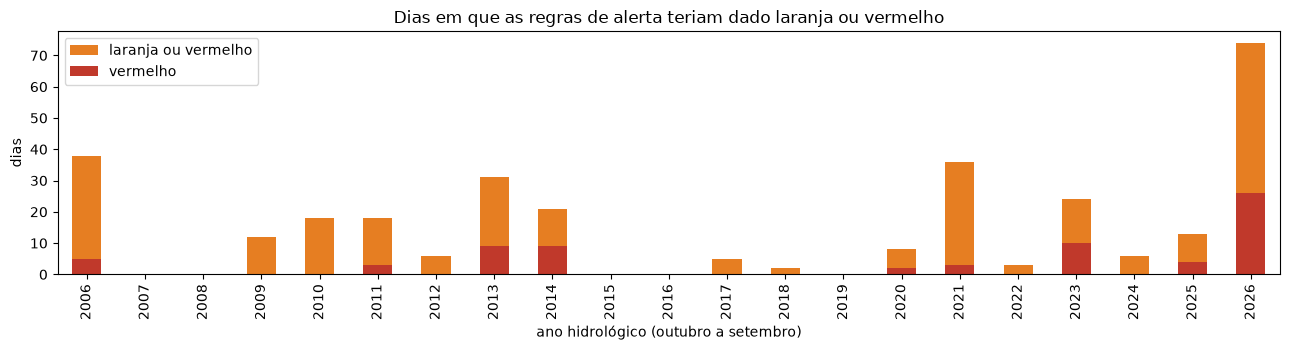

In [2]:
alerts = pd.read_csv(config.path(cfg, "series", "alertas_diarios.csv", mkdir=False), parse_dates=["date"])
alerts = alerts[alerts["date"] < "2026-10-01"]
alerts["ano_hidrologico"] = np.where(alerts["date"].dt.month >= 10, alerts["date"].dt.year + 1, alerts["date"].dt.year)
monthly = alerts.assign(month=alerts["date"].dt.to_period("M").astype(str)).groupby("month")["level"].max()
yearly = alerts.groupby("ano_hidrologico").agg(dias_laranja_ou_vermelho=("level", lambda s: int((s >= 2).sum())), dias_vermelho=("level", lambda s: int((s >= 3).sum())),
                                                caudal_maximo_m3s=("discharge_m3s", "max"), nivel_maximo=("level", "max"))
yearly.round(0).to_csv(REPORTS / "38_alertas_por_ano.csv")
facts = {"meses_analisados": len(monthly), "meses_com_alerta_laranja_ou_vermelho": int((monthly >= 2).sum()), "meses_com_alerta_vermelho": int((monthly >= 3).sum()),
         "anos_analisados": len(yearly), "anos_com_alerta_laranja_ou_vermelho": int((yearly["nivel_maximo"] >= 2).sum()), "anos_com_alerta_vermelho": int((yearly["nivel_maximo"] >= 3).sum()),
         "maior_caudal_m3s": float(yearly["caudal_maximo_m3s"].max()), "ano_do_maior_caudal": int(yearly["caudal_maximo_m3s"].idxmax())}
ax = yearly["dias_laranja_ou_vermelho"].plot.bar(figsize=(13, 3.6), color="#e67e22", label="laranja ou vermelho")
yearly["dias_vermelho"].plot.bar(ax=ax, color="#c0392b", label="vermelho"); ax.legend(); ax.set_ylabel("dias"); ax.set_xlabel("ano hidrológico (outubro a setembro)")
ax.set_title("Dias em que as regras de alerta teriam dado laranja ou vermelho")
plt.tight_layout(); plt.savefig(REPORTS / "38_dias_de_alerta_por_ano.png", dpi=110)
pd.Series(facts).to_frame("valor")

**De onde vêm os números.** As regras de alerta do projecto (notebook 32) aplicadas
ao caudal do GloFAS e à chuva na bacia, dia a dia. São "dias em que o sistema
teria avisado", não cheias confirmadas no terreno: antes de 2014 não há radar
para as confirmar.

## 2. Quem e o que está no caminho da água

In [3]:
exposure = operations.exposure(cfg)
exposure.round(1).to_csv(REPORTS / "38_exposicao_por_zona.csv")
places = pd.read_csv(config.path(cfg, "maps", "zonas_de_aviso", f"lugares_por_ordem_de_alagamento_{cfg['project']['aoi_name']}.csv", mkdir=False))
big = exposure.loc["zonas 1 e 2 (cheia grande)"]
facts.update({"area_alagada_cheia_grande_km2": float(big["area_km2"]), "terras_agricolas_km2": float(big["area_agricola_km2"]), "edificios": int(big["edificios"]),
              "estradas_km": float(big["estradas_km"]), "pessoas_worldpop_limite_superior": int(round(big["pessoas_worldpop_2020"], -2)),
              "lugares_que_alagam_primeiro": int((places["categoria"] == "alaga primeiro").sum()), "lugares_em_cheia_grande": int((places["categoria"] == "alaga em cheia grande").sum())})
exposure.T

zona,zona 1 (primeiras a alagar),zonas 1 e 2 (cheia grande)
area_km2,42.500,238.600
area_agricola_km2,11.700,46.300
edificios,40.000,"1,935.000"
escolas,0.000,1.000
unidades_de_saude,0.000,1.000
estradas_km,5.400,231.700
pessoas_worldpop_2020,"1,180.600","24,734.200"


**De onde vêm os números.** A zona é onde a água chegou na cheia de janeiro de 2026
(mapas do Copernicus EMS). Os edifícios vêm do Google Open Buildings, as estradas
do OpenStreetMap.

**As pessoas são um limite superior.** O WorldPop espalha a população por todo o
terreno, e numa planície com poucas casas dá gente a mais. O número de edifícios
é o dado mais sólido.

## 3. A água do rio: está a mudar?

,nome,tendencia,inclinacao_por_decada,p,leitura
troco,,,,,
Q1,Q1 fronteira / Ressano Garcia,sobe,0.225,0.000,um só satélite: válida para o período medido
Q2,Q2 km 37 a 74,sobe,0.115,0.000,um só satélite: válida para o período medido
Q3,Q3 km 74 a 110,desce,-0.073,0.000,um só satélite: válida para o período medido
Q4,Q4 Magude,sem tendência,0.014,0.555,
Q5,Q5 Xinavane,sobe,0.046,0.019,um só satélite: válida para o período medido
Q6,Q6 km 184 a 221,sem tendência,0.021,0.184,
Q7,Q7 Manhiça,desce,-0.017,0.027,não confirmada: pode vir da mudança de satélite
Q8,Q8 Marracuene,desce,-0.019,0.005,não confirmada: pode vir da mudança de satélite
Q9,Q9 foz / estuário,sem tendência,-0.009,0.237,


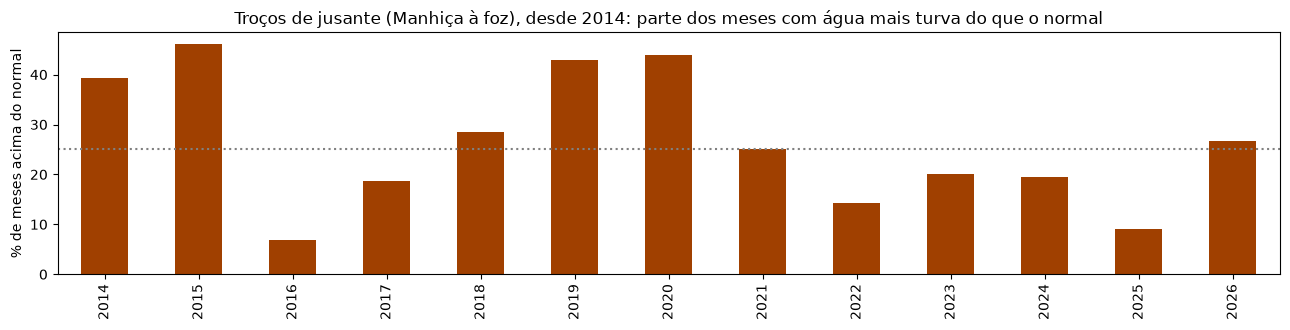

In [4]:
data, skill, _ = Q.expected_turbidity(cfg, Q.monthly_dataset(cfg))
trend = Q.trends(data, values=("ndti",))
full = trend[trend["periodo"] == "registo completo"].set_index("troco")
recent = data[data["month"] >= "2013-04"]            # one satellite family (Landsat 8/9), so years can be compared
anomaly = Q.anomalies(recent, "ndti")
high = anomaly[(anomaly["classe"] != "sem dados") & (anomaly["ano"] >= 2014)].assign(alto=lambda d: d["classe"] != "normal")
by_year = high[high["troco"].isin(["Q7", "Q8", "Q9"])].groupby("ano")["alto"].mean()
facts.update({"trocos_analisados": int(data["troco"].nunique()), "trocos_com_20_anos": int(data.groupby("troco")["landsat_utilizavel"].first().sum()),
              "trocos_com_tendencia_confirmada_de_subida": int(((full["tendencia"] == "sobe") & full["leitura"].str.startswith("confirmada")).sum()),
              "trocos_com_tendencia_confirmada_de_descida": int(((full["tendencia"] == "desce") & full["leitura"].str.startswith("confirmada")).sum()),
              "ano_com_mais_meses_turvos_a_jusante": int(by_year.idxmax()), "parte_dos_meses_turvos_nesse_ano": float(by_year.max()),
              "estacoes_publicas_de_qualidade_na_bacia": 0})
ax = (100 * by_year).plot.bar(figsize=(13, 3.4), color="#a04000"); ax.axhline(25, color="grey", linestyle=":"); ax.set_ylabel("% de meses acima do normal"); ax.set_xlabel("")
ax.set_title("Troços de jusante (Manhiça à foz), desde 2014: parte dos meses com água mais turva do que o normal")
plt.tight_layout(); plt.savefig(REPORTS / "38_meses_turvos_por_ano.png", dpi=110)
full[["nome", "tendencia", "inclinacao_por_decada", "p", "leitura"]]

## 4. A ficha

In [5]:
pd.Series(facts).to_frame("valor").to_csv(REPORTS / "38_factos.csv")
n = lambda v: f"{v:,.0f}".replace(",", " ")
sheet = f"""# Ficha de evidência do problema

Projecto Eyes to Earth (tarefa W3-09). Gerada pelo notebook 38 em {pd.Timestamp.now():%d/%m/%Y}.
Todos os números vêm dos dados do projecto; a origem de cada um está indicada.

## Cheias sem aviso

| Facto | Número | Origem |
|---|---|---|
| Anos (de outubro a setembro) em que o rio passou o limite laranja | **{facts['anos_com_alerta_laranja_ou_vermelho']} em {facts['anos_analisados']}** | regras de alerta sobre o caudal GloFAS e a chuva, 2006–2026 |
| Anos em que passou o limite vermelho | **{facts['anos_com_alerta_vermelho']} em {facts['anos_analisados']}** | idem |
| Meses com alerta laranja ou vermelho | **{facts['meses_com_alerta_laranja_ou_vermelho']} em {facts['meses_analisados']}** | idem |
| Maior caudal do período | **{n(facts['maior_caudal_m3s'])} m³/s em {facts['ano_do_maior_caudal']}** | GloFAS (modelo, não estação) |
| Antecedência que o sistema teria dado em janeiro de 2026 | **4 a 5 dias** antes do primeiro mapa de cheia | notebook 32 |

## O que está no caminho da água (cheia de janeiro de 2026, dentro do distrito)

| Facto | Número | Origem |
|---|---|---|
| Área alagada | **{n(facts['area_alagada_cheia_grande_km2'])} km²** | Copernicus EMS (EMSR857) |
| Terras agrícolas alagadas | **{n(facts['terras_agricolas_km2'])} km²** | ESA WorldCover |
| Edifícios na zona alagada | **{n(facts['edificios'])}** | Google Open Buildings |
| Estradas e caminhos na zona alagada | **{n(facts['estradas_km'])} km** | OpenStreetMap |
| Pessoas na zona alagada | **até cerca de {n(facts['pessoas_worldpop_limite_superior'])}** (limite superior) | WorldPop 2020; ver nota |
| Lugares com nome que alagam primeiro / em cheia grande | **{facts['lugares_que_alagam_primeiro']} / {facts['lugares_em_cheia_grande']}** | OpenStreetMap e GeoNames, por validar |

## Água cuja qualidade ninguém acompanha

| Facto | Número | Origem |
|---|---|---|
| Estações públicas de qualidade da água na bacia do Incomáti | **{facts['estacoes_publicas_de_qualidade_na_bacia']}** | arquivo mundial GEMStat (UNEP), fevereiro de 2026 |
| Troços do rio agora acompanhados por satélite | **{facts['trocos_analisados']}**, da fronteira à foz | Módulo Q |
| Troços com 20 anos de registo | **{facts['trocos_com_20_anos']}** (os de jusante; a montante o rio é estreito e só há dados desde 2017) | notebook 29 |
| Ano com mais meses de água turva a jusante, desde 2014 | **{facts['ano_com_mais_meses_turvos_a_jusante']}** ({100 * facts['parte_dos_meses_turvos_nesse_ano']:.0f} % dos meses acima do normal) | notebook 36 |
| Troços com tendência de 20 anos confirmada de água mais turva | **{facts['trocos_com_tendencia_confirmada_de_subida']}** (os dados não mostram que o rio esteja a ficar mais turvo) | Mann-Kendall sazonal, notebook 36 |

## Notas para usar estes números

- "Anos em que o rio passou o limite" são anos em que o sistema teria avisado. Não são
  cheias confirmadas uma a uma no terreno.
- As pessoas vêm de um mapa que espalha a população por todo o terreno. Numa planície com
  poucas casas dá gente a mais; dizer sempre "até cerca de".
- A área alagada é a da zona que o Copernicus analisou (58 % do distrito), mais a zona
  estimada pelo Modelo A fora dela.
- O satélite vê a cor da água. Não diz se a água é segura.
"""
(ROOT / "docs" / "ficha_de_evidencia_do_problema.md").write_text(sheet)
print(sheet)

# Ficha de evidência do problema

Projecto Eyes to Earth (tarefa W3-09). Gerada pelo notebook 38 em 11/10/2026.
Todos os números vêm dos dados do projecto; a origem de cada um está indicada.

## Cheias sem aviso

| Facto | Número | Origem |
|---|---|---|
| Anos (de outubro a setembro) em que o rio passou o limite laranja | **16 em 21** | regras de alerta sobre o caudal GloFAS e a chuva, 2006–2026 |
| Anos em que passou o limite vermelho | **9 em 21** | idem |
| Meses com alerta laranja ou vermelho | **43 em 249** | idem |
| Maior caudal do período | **2 987 m³/s em 2026** | GloFAS (modelo, não estação) |
| Antecedência que o sistema teria dado em janeiro de 2026 | **4 a 5 dias** antes do primeiro mapa de cheia | notebook 32 |

## O que está no caminho da água (cheia de janeiro de 2026, dentro do distrito)

| Facto | Número | Origem |
|---|---|---|
| Área alagada | **239 km²** | Copernicus EMS (EMSR857) |
| Terras agrícolas alagadas | **46 km²** | ESA WorldCover |
| Edifícios na zona al